# 文本 03：调参—完善—自行建模

三种任务共用真实评论、固定划分、词表和训练工具，逐步增加学生承担的工作。

| 等级 | 已经提供 | 完成条件 | 系数 |
|---|---|---|---|
| 一级 调参 | 完整普通 RNN | 基线、两组学习率粗筛、一次依据曲线提出的后续单参数实验；解释结果 | 0.8 |
| 二级 完善 | LSTM 框架和三个 TODO | 补全、通过读出及梯度检查，与同条件 RNN 比较并分析错例 | 0.9 |
| 三级 自行建模 | GRU 接口和设计提示 | 自己实现分类器；完成同一 GRU 的单因素设计对照 A/B，解释选择 | 1.0 |

二、三级独立开启，三级不依赖二级。等级依据实现和证据，不要求准确率逐级提高。允许 nn.LSTM/nn.GRU，不要求手写门控或优化器。

正式成绩 = **100 × 最终测试 Accuracy（0到1）× 所选模型所属等级系数**。例如 Accuracy=0.80，三级折算80分，二级72分，一级64分。Loss、F1、参数量和耗时用于分析，不额外加权。程序显示待教师核验的折算分；教师检查等级完成、独立实现和报告证据后认定等级。

先读 [文本01编码](01_文字如何变成序列.ipynb)。进入二级前，完成[原理04](../04_RNN_LSTM_GRU对比.ipynb)中的返回值形状和最小分类器练习。教师参考及历史图不作个人成绩。

> 本页为待完成作业。新版代码输出已清空，避免把旧末轮成绩当作新版最佳验证轮次成绩；末尾明确标注的历史图保留。每次从头运行生成独立目录，个人报告须引用自己的运行编号和CSV。默认运行一级学习率粗筛；后续调参记录和学生模型仍需自己完成。

In [ ]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict, replace
from datetime import datetime
import json
import sys
import uuid
import torch
from torch import nn
import matplotlib.pyplot as plt

LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或其子目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)

from rnn_lab import configure_chinese_font, seed_everything
from rnn_lab.text_data import load_text_data, build_vocab, encode_text, text_data_diagnostics
from rnn_lab.text_engine import (TextExperimentConfig, predict_text, evaluate_text_final,
                                 export_text_experiments_csv, save_text_run)
from rnn_lab.text_course import (make_tuned_config, run_course_experiment, check_student_model, check_design_pair, course_score)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion, plot_text_comparison,
                                text_examples)
from rnn_lab.teaching_visuals import (plot_text_levels, plot_text_model_steps,
                                     plot_validation_groups)

configure_chinese_font()
print("实验室：", LAB_DIR, "｜CPU 线程：", torch.get_num_threads())

In [ ]:
fig = plot_text_levels()
plt.show()
plt.close(fig)


## 参数与实验规则

先保持基线，再比较学习率候选；根据曲线决定下一次实验，不同时修改多个因素。

| 参数 | 起点 | 建议候选 | 观察重点 |
|---|---:|---|---|
| learning_rate | 0.003 | 0.001、0.003、0.005 | 下降速度、震荡与验证结果 |
| hidden_size / embedding_dim | 32 / 32 | 16、32、64 | 表示容量、参数量 |
| epochs | 6 | 3、6、10 | 学习不足或过拟合；记录保存轮次 |
| batch_size | 64 | 32、64、128 | 更新次数也会变化，不能只比轮数 |
| max_length | 100 | 60、100、140 | 截断比例与计算量 |
| num_layers | 1 | 1、2 | 深度与参数量 |
| optimizer | adam | adam、sgd、adamw | SGD默认momentum=0.9；各自需合适学习率 |
| weight_decay | 0 | 0、0.0001、0.001 | 正则化；AdamW为选做 |
| gradient_clip | 1.0 | 0.5、1.0、None | 裁剪前梯度与曲线；None表示不裁剪 |
| dropout | 0 | 0、0.1、0.3 | 仅用于至少两层循环网络；单层不生效 |

候选只是起点，不保证更好。交叉熵直接接 logits；不要在 forward 加 softmax。默认 CPU 单线程，不自动使用 GPU。

所有学生组用 **best_val_accuracy**：选验证准确率最高轮；同分选验证Loss更低轮，再同分选更早轮。完整曲线仍保留，训练预算按全部轮次记录。不得用曲线最高点配另一轮模型。

二级结构比较沿用基线训练条件。三级的 A/B 同用 GRU，仅改变读出、H、E或层数中的一项；与RNN的比较另作整体比较，不能代替A/B。

In [ ]:
RUN_LEVEL2 = False
RUN_LEVEL3 = False
RUN_HISTORICAL_REFERENCE = False
BASE_SETTINGS = dict(learning_rate=0.003, hidden_size=32, epochs=6,
                     batch_size=64, max_length=100, embedding_dim=32, num_layers=1)
base = TextExperimentConfig(name="一级 RNN 基线", cell_type="rnn", readout="last",
    dropout=0.0, optimizer="adam", weight_decay=0.0, gradient_clip=1.0,
    selection="best_val_accuracy", seed=42, device="cpu", **BASE_SETTINGS)
# 两组粗筛与基线仅有学习率不同；保持相同数据、种子和训练预算。
LR_CANDIDATES = [0.001, 0.005]
MY_PREDICTION = "待填写：三种学习率的曲线可能有什么差异，为什么？"
config_level2 = replace(base, name="二级 学生 LSTM", cell_type="lstm")
config_level3 = replace(base, name="三级 GRU A", cell_type="gru")
# 三级示范选题：last与masked mean；也可只选hidden_size/embedding_dim/num_layers之一。
DESIGN_PARAMETER = "readout"
DESIGN_VALUE = "mean"
config_level3_b = replace(config_level3, name="三级 GRU B", **{DESIGN_PARAMETER: DESIGN_VALUE})
RUN_DIR = LAB_DIR / "outputs" / "text" / "three_levels" / (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8])
RUN_DIR.mkdir(parents=True, exist_ok=False)
results, saved_dirs, trial_notes = {}, {}, {}
print("本次目录：", RUN_DIR)
print("运行前预测：", MY_PREDICTION)
(RUN_DIR / "prediction.json").write_text(json.dumps({"prediction": MY_PREDICTION,
    "learning_rates": [base.learning_rate, *LR_CANDIDATES]}, ensure_ascii=False, indent=2), encoding="utf-8")

## 数据和记录由三级共用

正式数据为现有真实评论的固定 train/val/test 划分；词表只由 **train** 建立，PAD=0、UNK=1。这里只打印标签、规模和诊断，训练与调参都查看验证集，最终测试在最后的独立单元显式开启。

人工短句仅用于说明或接口检查，不能混入正式训练，也不能替代验证指标。样例概率是模型的 softmax 输出，未经校准，不能读成“这个结论有同等程度的可靠性”。


In [ ]:
data = load_text_data(DATA_DIR)
vocab = build_vocab(record["text"] for record in data.splits["train"])
assert vocab["<PAD>"] == 0 and vocab["<UNK>"] == 1
print("数据版本：", data.version, "｜类别：", data.class_names)
print("固定划分：", {key: len(rows) for key, rows in data.splits.items()})
print("训练集词表大小：", len(vocab))
print("基线编码诊断：", text_data_diagnostics(data, vocab, base.max_length))

def keep_and_show(key, result):
    # 保存一组真正完成的运行，随后绘图；重跑不会覆盖之前的目录。
    if key in results:
        raise ValueError("此编号已运行，请使用新编号；修改方案后重启并从头执行。")
    results[key] = result
    destination = save_text_run(result, RUN_DIR / key)
    saved_dirs[key] = destination
    print()
    print(key, result["config"].name)
    print("配置：", asdict(result["config"]))
    print("验证：", {name: round(result["val_metrics"][name], 4)
                       for name in ("loss", "accuracy", "macro_f1")})
    print("保存轮次：", result["selected_epoch"], "｜实际更新次数：", result["optimizer_steps"])
    print("参数量：", result["parameter_count"], "｜训练与验证耗时/秒：",
          round(result["elapsed_seconds"], 3), "｜记录目录：", destination)
    for filename, draw in (("training_history.png", plot_text_history),
                           ("validation_confusion.png", plot_text_confusion)):
        fig = draw(result)
        fig.savefig(destination / filename, dpi=140, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    # 按验证集原顺序选择一个正确、两个错误样例，不按概率挑漂亮例子。
    examples = text_examples(result, correct=True, limit=1) + text_examples(result, correct=False, limit=2)
    for example in examples:
        print("验证样例：", example)
    (destination / "validation_examples.json").write_text(
        json.dumps(examples, ensure_ascii=False, indent=2), encoding="utf-8")
    export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
    return None

## 第一级 调参

提供完整 Embedding→RNN→有效句尾→Linear。先运行基线及两个学习率候选，观察训练/验证Loss、验证Accuracy/F1和梯度；然后填写后续实验。调参下降也如实记录，不要求每次都提升。

后续判断示例：训练与验证都未收敛，可检验学习率或轮数；训练继续下降而验证变差，可检验正则化；截断比例较高，可检验最大长度。这些是待检验假设，不能仅凭图就断定原因。

In [ ]:
fig = plot_text_model_steps("rnn", base.embedding_dim, base.hidden_size)
plt.show()
plt.close(fig)


In [ ]:
result_baseline = run_course_experiment(base, data, level=1, vocab=vocab)
keep_and_show("L1_baseline", result_baseline)


In [ ]:
for index, learning_rate in enumerate(LR_CANDIDATES, 1):
    trial_config = make_tuned_config(base, "learning_rate", learning_rate)
    key = f"L1_lr{index}"
    keep_and_show(key, run_course_experiment(trial_config, data, level=1, vocab=vocab))
    trial_notes[key] = {"parent": "L1_baseline", "parameter": "learning_rate", "value": learning_rate,
                        "reason": MY_PREDICTION}

### 先看粗筛，再决定下一次实验

下图比较本轮已经完成的一级组。不能只看一个Accuracy：引用曲线、保存轮次、参数量及更新次数说明判断。人工短句只用于额外观察，不计入正式指标。

In [ ]:
fig = plot_text_comparison([r for r in results.values() if r["course_level"] == 1])
fig.suptitle("第一级：RNN学习率粗筛｜同数据同预算")
fig.savefig(RUN_DIR / "level1_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

MY_REVIEWS = ["服务很贴心，下次还会再来。", "虽然位置不错，但是房间太吵，整晚没有睡好。"]
for review in MY_REVIEWS:
    print("人工句子：", review)
    for key in tuple(k for k in results if k.startswith("L1_")):
        output = predict_text(results[key], review)
        print(key, output["predicted_class"], output["probabilities"],
              "｜截断：", output["truncated"], "｜未知字数：", output["unknown_count"])
print("粗筛完成；正式完成一级还需下面的自主后续实验。")

### 根据观察提出后续实验

填写父实验编号、一个参数及新值、依据哪条曲线作出的预测。后续实验可以从任一已完成一级组出发，但每次只改一项。最低要求为一次有效后续实验；重复本格请使用新编号。

正式一级至少保留4组：基线、两个学习率候选、一次学生提出的后续实验。运行前先写理由，运行后在报告中写结论，不事后改写预测。

In [ ]:
FOLLOWUP_KEY = "L1_followup"
PARENT_KEY = "L1_baseline"  # 可改为L1_lr1或L1_lr2，须依据粗筛结果选择。
NEXT_PARAMETER = None      # 填入一个参数名，如"epochs"；不能只复制示范结论。
NEXT_VALUE = None
NEXT_REASON = "待填写：引用哪组曲线或指标，我预计调整后会怎样？"
if NEXT_PARAMETER is None:
    print("后续实验未完成：请填写参数、值和运行前理由；当前粗筛不能单独认定一级完成。")
else:
    if not NEXT_REASON.strip() or NEXT_REASON.startswith("待填写"):
        raise ValueError("请先写基于粗筛证据的预测。")
    if PARENT_KEY not in results or results[PARENT_KEY]["course_level"] != 1:
        raise ValueError("父实验必须是本次已完成的一级组。")
    next_config = make_tuned_config(results[PARENT_KEY]["config"], NEXT_PARAMETER, NEXT_VALUE)
    keep_and_show(FOLLOWUP_KEY, run_course_experiment(next_config, data, level=1, vocab=vocab))
    trial_notes[FOLLOWUP_KEY] = {"parent": PARENT_KEY, "parameter": NEXT_PARAMETER,
                               "value": NEXT_VALUE, "reason": NEXT_REASON}
    (RUN_DIR / "trial_notes.json").write_text(json.dumps(trial_notes, ensure_ascii=False, indent=2), encoding="utf-8")

## 第二级：补全 LSTM

在下一格 `StudentLSTMClassifier` 中完成三处 TODO，之后把参数区 `RUN_LEVEL2` 改为 `True`。只补模型代码，词表、训练、绘图和导出仍由公共流程完成。

| TODO | 需要完成 | 输入与输出 | 提示和常见错误 |
|---|---|---|---|
| 1：`build_recurrent` | 构造并返回 LSTM 层 | E→H；配置中的 L 为层数 | 允许 `nn.LSTM`；采用 `batch_first=True`、单向；单层的层间 dropout 为 0。不要把 B/T 当输入维度 |
| 2：`recurrent_steps` | 把字向量送入 LSTM，返回全部时间步输出 | `[B,T,E]`→`[B,T,H]` | LSTM 返回 `output,(h_n,c_n)`。本方法只返回 output；不要把二元组直接送给 Linear |
| 3：`classify_last` | 每句选出有效句尾，送入已提供的分类层 | `[B,T,H]`和`[B]`→`[B,2]` | 可使用按行索引或 gather。长度从 1 开始、位置从 0 开始；索引与张量应在同设备。不要取补齐后的最右列，不提前 softmax |

**小例子**：两句编码后的有效长度为 `[2,4]`，矩形宽度为 4。第一句应取其第 2 个状态，第二句取第 4 个状态；给右侧再加三格 PAD，两个有效位置都不变。这是接口探针，不是训练样本。

检查顺序：先确认 TODO 1 的层属性，再看 TODO 2 的 B/T/H，最后核对 TODO 3 的有效长度。不要用更高准确率来代替接口检查。


In [ ]:
fig = plot_text_model_steps("lstm", config_level2.embedding_dim, config_level2.hidden_size)
plt.show()
plt.close(fig)


In [ ]:
class StudentLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, config):
        super().__init__()
        self.cell_type = "lstm"
        self.readout = "last"
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        self.classifier = nn.Linear(config.hidden_size, n_classes)
        self.recurrent = self.build_recurrent(config)

    def build_recurrent(self, config):
        # TODO 1：返回 E→H 的单向 nn.LSTM，B 在首轴；层数/dropout 与 config 一致。
        # 输入：config；输出：一个 nn.LSTM 层。检查其 input_size/hidden_size/batch_first。
        raise NotImplementedError("二级 TODO 1：请构造并返回 LSTM 层，使用配置中的 E/H/层数。")

    def recurrent_steps(self, embedded):
        # TODO 2：接通已定义循环层，只返回全部时间步 output。
        # 输入：[B,T,E]；输出：[B,T,H]。注意 LSTM 的 (h_n,c_n) 是另一项返回值。
        raise NotImplementedError("二级 TODO 2：请将 Embedding 接入 LSTM，并返回 [B,T,H] 全部输出。")

    def classify_last(self, outputs, lengths):
        # TODO 3：每条按有效长度取句尾，然后使用已经提供的 self.classifier。
        # 输入：[B,T,H] 与 [B]；输出：[B,2] logits；排除 PAD，不使用 softmax。
        raise NotImplementedError("二级 TODO 3：请按每句有效长度读出状态并分类，返回 [B,2] logits。")

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        outputs = self.recurrent_steps(embedded)
        return self.classify_last(outputs, lengths)


### 检查通过，再训练

`check_student_model` 使用人工 ID 小批次检查 `[B,2]`、有限数值、增加右侧 PAD 不变、短句单独/混入长句批次不变。它**不是评分函数，也不评价正式数据**。未补齐时明确停在 TODO；不会自动换成已经完成的教师 LSTM。

结构比较使用基线 RNN 的同一数据、E/H、轮数、学习率和随机种子；不同结构的权重形状不同，固定种子不代表完全相同的初始化。结果需要记录真实参数量。


新增检查会注入不同数值的人工循环输出，核对有效句尾；还检查 Embedding、循环层、分类层的梯度连接。只用人工小张量，不更新权重、不评价正式数据。检查保持模型模式、参数、已有梯度和随机状态。它仍不能替代教师对独立实现的验收。

In [ ]:
if RUN_LEVEL2:
    seed_everything(config_level2.seed)
    student_lstm = StudentLSTMClassifier(len(vocab), data.n_classes, config_level2)
    level2_check = check_student_model(student_lstm, data.n_classes, "lstm")
    print("二级人工接口检查：", level2_check)
    result_lstm = run_course_experiment(
        config_level2, data, level=2, vocab=vocab, model=student_lstm)
    keep_and_show("L2_lstm", result_lstm)
    (saved_dirs["L2_lstm"] / "interface_check.json").write_text(
        json.dumps(level2_check, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    print("第二级未开展：打开 RUN_LEVEL2 前，请完成 StudentLSTMClassifier 的 3 处 TODO。")


## 第三级：自主搭建 GRU

这一格只提供模型接口，你需要自己搭建完整分类器。可以使用 **`nn.GRU`**，无需手写门控方程、反向传播或优化器。不能继承已完成的公共 `TextClassifier`，也不能通过修改 `cell_type` 调用参考成品来替代本级。

建议按四步完成：

1. **确定输入和输出。**`token_ids` 是 int64 `[B,T]`，`lengths` 是 int64 `[B]`；返回浮点 `[B,2]` 原始 logits。
2. **先画结构。**最小可行方向为 Embedding→单层单向 GRU→有效句尾→Linear。若选择 mean，必须明确排除 PAD。
3. **定义各层并记录设计。**自行设置 `self.embedding`、`self.recurrent`、`self.classifier`；`self.cell_type="gru"`，`self.readout` 记为 `"last"` 或 `"mean"`。这些属性供检查、预测和实验记录使用。
4. **连接 forward，再用小样本检查。**GRU 返回 `output,h_n`，没有 LSTM 的 c_n；有效 last 与 masked mean 都不能把 PAD 混入句子表示。

E/H/层数/读出是你的设计决定，但必须与 `config_level3` 一致。统一接口采用 `batch_first=True`、单向网络；单层层间 dropout 为 0。建议先保持默认预算并实现 last，跑通后再提出有理由的选择。

在下面 Markdown 中先写自己的结构和理由，再实现模型。第三级独立于第二级：即使 LSTM 尚未补完，也可以单独开启 `RUN_LEVEL3`。


**本级必须完成A/B设计对照。**先实现可运行的GRU A，再提出一个设计变化形成B。推荐 last/mean；也可选择H、E或层数。A/B的数据、词表、学习率、优化器、batch、最大长度、轮数、种子及选轮规则相同。不要只把二级LSTM换成GRU就宣布完成三级。自定义classifier可放在该模块内；句子读出必须直接送入classifier，以便语义核验。

A/B效果持平或下降不影响完成资格；解释变化与局限。两组都必须通过检查。至少分析一条验证错例，另与RNN比较时说明变了哪些条件。

In [ ]:
fig = plot_text_model_steps("gru", config_level3.embedding_dim, config_level3.hidden_size)
plt.show()
plt.close(fig)


### 我的设计记录（运行前编辑本格）

- 模型结构与各步张量形状：待填写。
- A与B唯一改变的因素、原值和新值：待填写。
- 为什么选择这个变化，预计影响什么：待填写。
- 两组共同条件、预算和预先确定的选择规则：待填写。
- 运行后的结果、参数量、保存轮次及错例分析：待运行后填写。

默认题为last/mean，模型必须依据config.readout实现两条正确读出；对应代码由学生完成。若改H、E或层数，在参数区同步修改。禁止仅改CSV中的配置名称。

In [ ]:
class StudentGRUClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, config):
        super().__init__()
        # 自主设计：定义 embedding/recurrent/classifier，记录 cell_type/readout。
        # 允许 nn.GRU；E/H/L/读出需与 config 一致；不能继承完整参考分类器。
        raise NotImplementedError("三级模型构造：请自行定义 Embedding、GRU、分类层及模型属性。")

    def forward(self, token_ids, lengths):
        # 自主设计：从 [B,T] 与 [B] 到 [B,2] logits，正确处理有效长度。
        raise NotImplementedError("三级前向传播：请自行连接各层、处理有效读出，返回 [B,2] logits。")


In [ ]:
if RUN_LEVEL3:
    changed = check_design_pair(config_level3, config_level3_b)
    print("三级唯一设计变化：", changed)
    for key, config in (("L3_A", config_level3), ("L3_B", config_level3_b)):
        seed_everything(config.seed)
        student_gru = StudentGRUClassifier(len(vocab), data.n_classes, config)
        check = check_student_model(student_gru, data.n_classes, "gru")
        result = run_course_experiment(config, data, level=3, vocab=vocab, model=student_gru)
        keep_and_show(key, result)
        (saved_dirs[key] / "interface_check.json").write_text(json.dumps(check, ensure_ascii=False, indent=2), encoding="utf-8")
    fig = plot_text_comparison([results["L3_A"], results["L3_B"]])
    fig.suptitle("三级GRU设计对照 A/B｜唯一变化：" + changed)
    fig.savefig(RUN_DIR / "level3_design_comparison.png", dpi=140, bbox_inches="tight")
    plt.show(); plt.close(fig)
else:
    print("三级未开展：先填写设计，再完成GRU构造和forward；独立于二级。")

## 汇总自己的实际运行，准备一份报告

下图只比较本次真正完成的组，未开展等级不会生成空成绩。`all_experiments.csv` 记录配置、实际循环层、参数量、耗时和验证指标；各组目录保存配置、模型参数、预处理、历史曲线和样例记录。

建议从基础模型中选一条你能解释的验证错例，检查是否截断、是否有未知字、是否存在否定或转折。这里的分组图只帮助看现象，不能单凭相关性断定错误原因。

一份 [实验报告模板](../../docs/03_RNN模型组合探索实验报告模板.docx) 按实际完成内容填写：一级写调参比较；二级追加补全位置和检查；三级追加结构、设计理由与结果。未开展写明即可，不必为每本 Notebook 另交报告。提交一份学校格式 Word 主报告，并附本人 Notebook 和 all_experiments.csv；图按需放入报告。模型、预处理、逐轮history、检查和预测记录留在个人运行目录备查。


选做稳定性复核：在测试前固定候选和种子列表，例如42/7/2026，重建并分别训练，汇总验证结果均值与范围，不能挑最好种子作为最终成绩。正式提交模型的种子预先固定为42。

In [ ]:
fig = plot_text_comparison(list(results.values()))
fig.suptitle("本次三级实验汇总｜仅显示真正完成的运行，指标来自验证集")
fig.savefig(RUN_DIR / "completed_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

fig = plot_validation_groups(results["L1_baseline"])
fig.savefig(RUN_DIR / "level1_validation_groups.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

csv_path = export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
print("真正完成的运行：", list(results))
print("汇总 CSV：", csv_path)
print("各组记录：", {key: str(path) for key, path in saved_dirs.items()})


## 2026-10-17 历史参考：旧任务图与原始输出

以下两幅图是旧版“基础 A / 提高 B / 进阶 C / 手写 D”任务的**教师参考图**，不代表本次三级实验的成绩或完成要求。它们仅用于理解当时的任务拆分和文本流程。

原执行日期为 2026-10-17；原单元 ID 和图片输出保留。第一幅为 `plot_assignment_route("text")` 的旧路线示意，第二幅为 `plot_text_pipeline()` 的流程示意，都是人工绘制的讲解图，不是训练得到的指标。完整原始 Notebook、旧任务代码及来源清单见 [历史快照](reference/20261017/03_自主修改与挑战.ipynb) 与 [快照清单](reference/20261017/manifest.json)。

默认关闭重新绘制；既有图片供直接阅读。若主动开启 `RUN_HISTORICAL_REFERENCE`，只重新画这两幅历史图，不训练参考模型。当前正式任务以本页前面的三个等级为准。


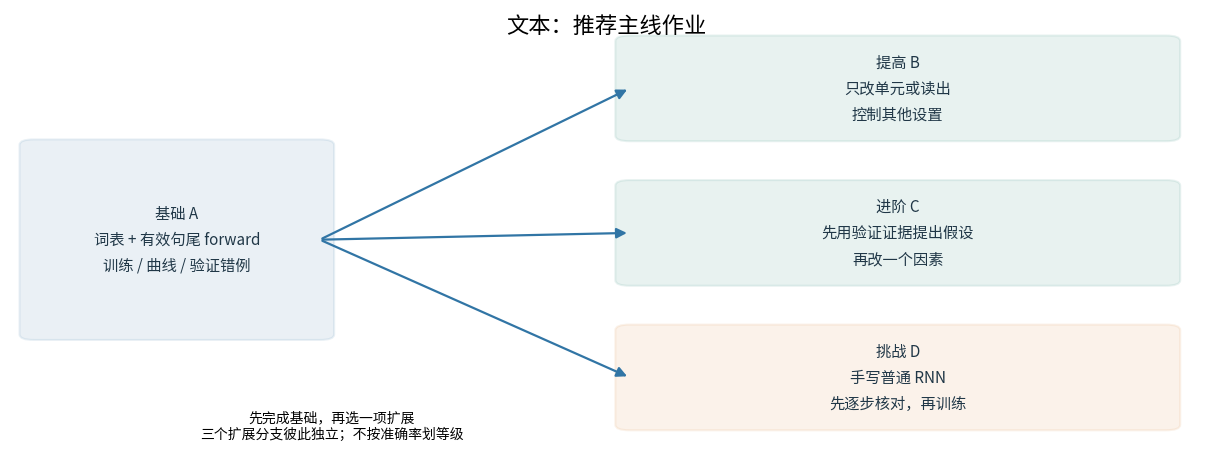

In [2]:
if RUN_HISTORICAL_REFERENCE:
    from rnn_lab.teaching_visuals import plot_assignment_route
    import matplotlib.pyplot as plt

    fig = plot_assignment_route("text")
    plt.show()
    plt.close(fig)


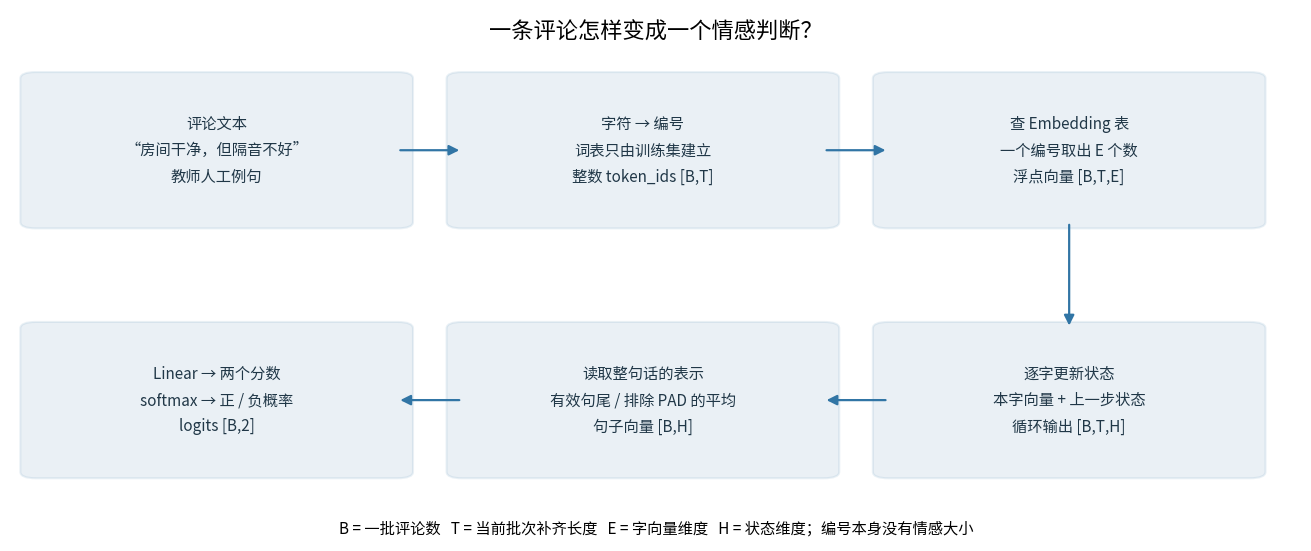

In [3]:
if RUN_HISTORICAL_REFERENCE:
    from rnn_lab.teaching_visuals import plot_text_pipeline
    import matplotlib.pyplot as plt

    fig = plot_text_pipeline()
    plt.show()
    plt.close(fig)


## 正式提交 先固定方案再测试和折算

探索时保持关闭；**正式提交必须对选定的一组模型执行最终测试**。先根据验证结果选择，不能逐个测试后挑最高分。默认选择占位值为空，避免误测基线。

一级需粗筛和自主后续实验；二级需本人补全代码、检查和与基线比较；三级需本人模型和A/B对照。最终系数跟随选定模型所属等级，不能拿一级模型乘三级系数。固定模型、预处理、seed=42、最佳验证轮次及选择理由后，再查看测试。

程序折算分为100×测试Accuracy×0.8/0.9/1.0，显示两位小数；F1、Loss和耗时不另加权。教师核验等级完成和独立实现后确认成绩。

In [ ]:
RUN_FINAL_TEST = False
SELECTED_KEY = ""  # 从实际results中选定一组，不能按测试成绩回头改选。
SELECTION_REASON = "待填写：依据哪些验证结果、设计对照和实验目的选定？"
COMPLETION_CONFIRMED = False  # 完成所属等级的代码、实验和报告后改True，教师仍会核验。
if RUN_FINAL_TEST:
    if SELECTED_KEY not in results:
        raise ValueError("请选择本次实际完成的一组。")
    if not COMPLETION_CONFIRMED or not SELECTION_REASON.strip() or SELECTION_REASON.startswith("待填写"):
        raise ValueError("请完成等级要求并先填写验证选型理由。")
    selected = results[SELECTED_KEY]
    level = selected["course_level"]
    if selected["config"].seed != 42:
        raise ValueError("正式提交使用预先固定的seed=42，其他种子仅作验证复核。")
    if level == 1 and (len([r for r in results.values() if r["course_level"] == 1]) < 4 or not any(k.startswith("L1_followup") for k in trial_notes)):
        raise ValueError("一级需基线、两组粗筛和一次有预测记录的后续实验。")
    if level == 3 and not {"L3_A", "L3_B"} <= results.keys():
        raise ValueError("三级需完成A/B设计对照，不能只提交一个GRU。")
    selection_path = RUN_DIR / "selection_frozen.json"
    # 在测试之前写入冻结记录；重复运行只允许同一选择。
    frozen = {"selected_key": SELECTED_KEY, "reason": SELECTION_REASON,
              "course_level": level, "config": asdict(selected["config"]),
              "selected_epoch": selected["selected_epoch"], "test_evaluated_at_freeze": False}
    if selection_path.exists() and json.loads(selection_path.read_text(encoding="utf-8")) != frozen:
        raise ValueError("本次方案已冻结，不能根据测试结果改选。")
    selection_path.write_text(json.dumps(frozen, ensure_ascii=False, indent=2), encoding="utf-8")
    final = evaluate_text_final(selected)
    score = course_score(selected)
    print("最终测试：", {k: final[k] for k in ("accuracy", "macro_f1", "loss")})
    print("所属等级：", level, "系数：", score["coefficient"], "待验收折算分：", round(score["provisional_score"], 2))
    (RUN_DIR / "final_selection.json").write_text(json.dumps({**frozen, **score}, ensure_ascii=False, indent=2), encoding="utf-8")
    save_text_run(selected, RUN_DIR / "final_selected")
else:
    print("探索阶段：未测测试集。正式提交前须完成等级要求、冻结方案并执行本格。")
export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
plt.close("all")